# M–c Relation Recovery — Triaxial NFW Lensing Test

Generates mock clusters with concentrations drawn from the **Dutton & Maccio (2014)**
mass–concentration relation, simulates the full weak-lensing signal using **triaxial NFW
shear** (random CDM-like axis ratios + isotropic line-of-sight orientations), and
tests whether the destacking likelihood recovers the input M–c parameters
$(c_0, \alpha, \beta)$ from per-cluster $\Delta\Sigma$ profiles.

The fitting model is still **spherical NFW** — the test probes how triaxiality
biases M–c recovery when clusters have random orientations.

**Priors**: Gaussian on $c_0$, $\alpha$, $\beta$, and $\log M_{\rm norm}$.

**Bias suppression**: `scatter_logc=0` (no Jensen bias) and `poisson_richness=False`
(no errors-in-variables bias), so any recovered bias is purely from triaxiality.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table

from destacking.simulation import generate_truth_catalog, make_test_data
from destacking.fitting import run_sampler_mc
from destacking.relations import c_DuttonMaccio
from destacking.model import _MC_M_PIVOT_LOG, _MC_Z_REF

from xlensing.sims import (
    make_simple_random_cat,
    apply_triaxial_NFW_shear_region,
    r_vir,
    project_ellipsoid,
)
from xlensing.data import metacal_cluster_lensing, signal
import ngmix

try:
    import corner
except ImportError:
    corner = None

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(it, **kwargs): return it

Lookup tables loaded!


## Parameters

In [2]:
N_CLUSTERS   = 5000          # number of clusters (increase for tighter posteriors)
RADII        = np.logspace(-0.8, 0.8, 12)   # projected radii [Mpc]
SEED         = 42

# ── Galaxy survey parameters ──
DENSITY         = 120        # source density parameter for make_simple_random_cat
WIDTH_RAD       = 0.006     # field half-width [rad] ≈ ±20 arcmin
Z_SRC_RANGE     = (0.4, 1.5)
SHAPE_NOISE     = 0.25      # per-component rms (GPriorBA sigma)
NOISE_FLOOR_COV = 1e4       # [(M_sun/pc²)²] for empty radial bins

# Bin limits — edges offset by half a bin width so RADII fall at centres
log_r  = np.log10(RADII)
dlog   = np.diff(log_r)[0]
edges  = np.logspace(log_r[0] - dlog/2, log_r[-1] + dlog/2, len(RADII) + 1)
bin_limits = np.column_stack([edges[:-1], edges[1:]])
N_BINS = len(RADII)

print(f'Radii: {RADII.round(3)}')
print(f'M_pivot_log = {_MC_M_PIVOT_LOG},  z_ref = {_MC_Z_REF}')

Radii: [0.158 0.222 0.31  0.433 0.605 0.846 1.182 1.653 2.31  3.229 4.514 6.31 ]
M_pivot_log = 14.0,  z_ref = 0.35


## 1 — Generate truth catalog

Concentrations from Dutton & Maccio (2014), no scatter and no magnitude-gap
dependence.  The "true" M–c parameters $(c_0, \alpha, \beta)$ are extracted by
an OLS fit to $\log_{10}c$ over the sample at the sample's masses and redshifts.

In [3]:
truth = generate_truth_catalog(
    N_CLUSTERS,
    z_range=(0.2, 0.6),
    logM_range=(13.5, 15.0),
    delta_m_gamma=0.0,   # no magnitude-gap dependence on concentration
    scatter_logc=0.0,    # zero scatter → no Jensen bias
    seed=SEED,
)

# OLS fit of log10(c) = log10(c0) + alpha*(log10(M)-M_piv) + beta*log10((1+z)/(1+z_ref))
# over the truth catalog to extract sample-level truth values
logM_s  = np.log10(truth['M_halo'])
logc_s  = np.log10(truth['concentration'])
logz1_s = np.log10((1.0 + truth['z']) / (1.0 + _MC_Z_REF))
X = np.column_stack([np.ones(N_CLUSTERS), logM_s - _MC_M_PIVOT_LOG, logz1_s])
coeffs, *_ = np.linalg.lstsq(X, logc_s, rcond=None)
logc0_true, alpha_true, beta_true = coeffs
c0_true = 10.0 ** logc0_true

print(f'Saved {N_CLUSTERS} clusters')
print(f'DM truth:  c0={c0_true:.3f},  alpha={alpha_true:.4f},  beta={beta_true:.4f}')
truth[:5]

Saved 5000 clusters
DM truth:  c0=4.566,  alpha=-0.0909,  beta=-0.4687


z,M_halo,concentration,M_BCG,L_BCG,L_brightest_sat,delta_m,N_sat
float64,float64,float64,float64,float64,float64,float64,int64
0.5095824194223852,37064115898153.92,4.7355557773933805,139663267345.2454,651698541.121522,417471280.58792156,0.4835503617253429,6
0.3755513759008209,65259167271121.734,4.712510728940385,495939029149.92773,4173120254.440037,3757792747.8748274,0.11382018941124342,23
0.5434391679645529,76123309837349.92,4.397409889842687,537051327418.9192,4512516762.021015,2539046835.8487463,0.6243702902139779,21
0.47894721162374554,35585935110455.016,4.803126657311718,223540558082.31012,1529177325.4080374,1412142242.3268814,0.08644851284268604,8
0.23767093915505982,32505409935814.195,5.273122022019668,304070052108.54895,2379157488.3397813,230667564.7634759,2.533591651154298,3


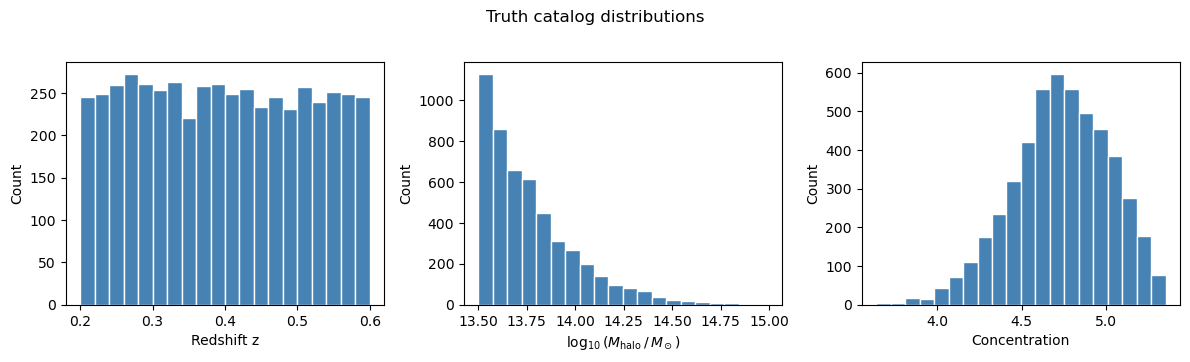

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

axes[0].hist(truth['z'], bins=20, color='steelblue', edgecolor='white')
axes[0].set_xlabel('Redshift z')

axes[1].hist(np.log10(truth['M_halo']), bins=20, color='steelblue', edgecolor='white')
axes[1].set_xlabel(r'$\log_{10}(M_{\rm halo}\,/\,M_\odot)$')

axes[2].hist(truth['concentration'], bins=20, color='steelblue', edgecolor='white')
axes[2].set_xlabel('Concentration')

for ax in axes: ax.set_ylabel('Count')
plt.suptitle('Truth catalog distributions', y=1.02)
plt.tight_layout(); plt.show()

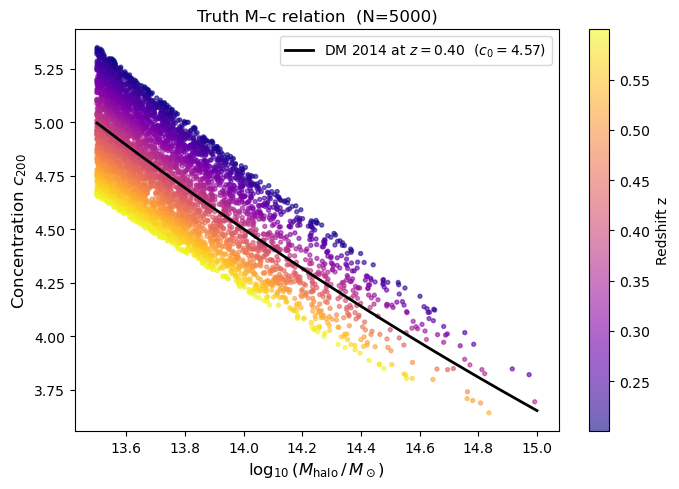

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))

sc = ax.scatter(
    logM_s, truth['concentration'],
    c=truth['z'], cmap='plasma', s=8, alpha=0.6,
    rasterized=True,
)
plt.colorbar(sc, ax=ax, label='Redshift z')

z_med  = float(np.median(truth['z']))
M_grid = np.logspace(13.5, 15.0, 200)
C_grid = c_DuttonMaccio(z_med * np.ones(200), M_grid)
ax.plot(np.log10(M_grid), C_grid, 'k-', lw=2,
        label=rf'DM 2014 at $z={z_med:.2f}$  ($c_0={c0_true:.2f}$)')

ax.set_xlabel(r'$\log_{10}(M_{\rm halo}\,/\,M_\odot)$', fontsize=12)
ax.set_ylabel(r'Concentration $c_{200}$', fontsize=12)
ax.set_title(f'Truth M–c relation  (N={N_CLUSTERS})', fontsize=12)
ax.legend()
plt.tight_layout(); plt.show()

## 2 — Triaxial shapes and projected ellipses

Each cluster is assigned a random CDM-like triaxial shape and a random isotropic
line-of-sight direction.  `project_ellipsoid` returns the projected semi-axes
and position angle on the sky.

Projecting triaxial ellipsoids...
Projected q_min/q_maj:  median=0.68, range [0.30, 1.00]


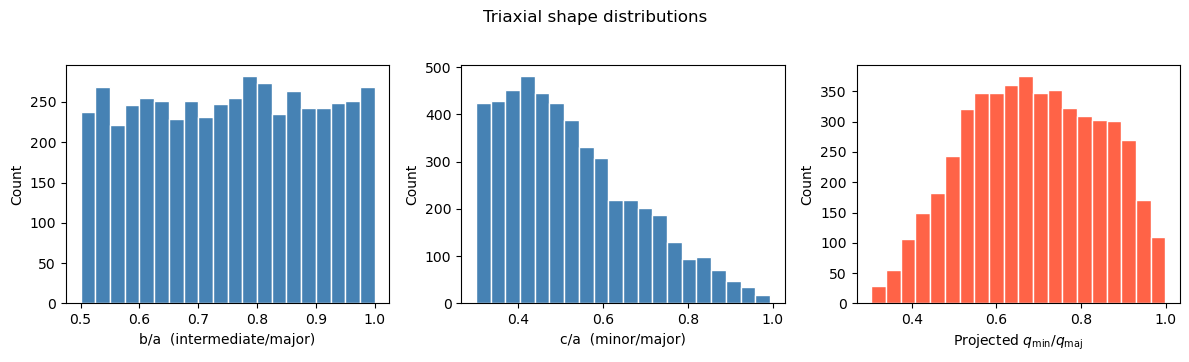

In [6]:
rng_tri = np.random.default_rng(SEED + 10)

r_vir_vals = np.array([
    r_vir(float(z), float(M))
    for z, M in zip(truth['z'], truth['M_halo'])
])

# CDM-like axis ratios: b/a ∈ (0.5, 1),  c/a ∈ (0.3, b/a)
q_ba = rng_tri.uniform(0.5, 1.0, N_CLUSTERS)
q_ca = rng_tri.uniform(0.3, q_ba)

# Isotropic random LOS directions
theta_los_arr = np.arccos(rng_tri.uniform(0.0, 1.0, N_CLUSTERS))
phi_los_arr   = rng_tri.uniform(0.0, 2 * np.pi, N_CLUSTERS)

print('Projecting triaxial ellipsoids...')
q_maj_arr = np.zeros(N_CLUSTERS)
q_min_arr = np.zeros(N_CLUSTERS)
pa_arr    = np.zeros(N_CLUSTERS)
for i in range(N_CLUSTERS):
    a = r_vir_vals[i]
    b, c = q_ba[i] * a, q_ca[i] * a
    q_maj_arr[i], q_min_arr[i], pa_arr[i] = project_ellipsoid(
        a, b, c, theta_los_arr[i], phi_los_arr[i]
    )

print(f'Projected q_min/q_maj:  '
      f'median={np.median(q_min_arr/q_maj_arr):.2f}, '
      f'range [{(q_min_arr/q_maj_arr).min():.2f}, {(q_min_arr/q_maj_arr).max():.2f}]')

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].hist(q_ba, bins=20, color='steelblue', edgecolor='white')
axes[0].set_xlabel('b/a  (intermediate/major)')
axes[1].hist(q_ca, bins=20, color='steelblue', edgecolor='white')
axes[1].set_xlabel('c/a  (minor/major)')
axes[2].hist(q_min_arr / q_maj_arr, bins=20, color='tomato', edgecolor='white')
axes[2].set_xlabel(r'Projected $q_{\rm min}/q_{\rm maj}$')
for ax in axes: ax.set_ylabel('Count')
plt.suptitle('Triaxial shape distributions', y=1.02)
plt.tight_layout(); plt.show()

## 3 — Simulate triaxial NFW lensing

For each cluster:
1. Draw fresh intrinsic shapes from `GPriorBA(σ=0.25)` into the base source field.
2. Apply triaxial NFW shear with `apply_triaxial_NFW_shear_region`.
3. Measure per-galaxy lensing with `metacal_cluster_lensing`.
4. Bin into $\Delta\Sigma(R)$ with `signal`; assign diagonal shape-noise covariance.

The angular-diameter-distance function is replaced with a fast spline before forking
the pool, so all workers inherit the optimised version via copy-on-write.

In [7]:
%%time
import multiprocess as mp
from scipy.interpolate import interp1d
import xlensing.cosmo as _xlc
import xlensing.sims as _xlsims

# ── 1. Spline-based DA (replaces slow scipy.quad per element) ──────────────
_z_tab    = np.linspace(0.0, 3.0, 5000)
_chi_tab  = _xlc.cosmology.comoving_distance(_z_tab).value
_chi_of_z = interp1d(_z_tab, _chi_tab, kind='linear',
                     bounds_error=False, fill_value='extrapolate')

def _DA_fast(z1, z2):
    z2_a = np.atleast_1d(np.asarray(z2, dtype=float))
    res  = (_chi_of_z(z2_a) - float(_chi_of_z(float(z1)))) / (1.0 + z2_a)
    return float(res[0]) if np.ndim(z2) == 0 else res

_xlc.DA    = _DA_fast
_xlsims.DA = _DA_fast

# ── 2. Background source field ─────────────────────────────────────────────
rng_base = np.random.default_rng(99)
base_cat = make_simple_random_cat(DENSITY, WIDTH_RAD, Z_SRC_RANGE,
                                  shape_noise=0.0, seed=0).T
N_GALS   = len(base_cat)

sizes  = rng_base.lognormal(mean=np.log(0.5), sigma=0.5, size=N_GALS)
R_RESP = np.clip(1.0 - (sizes / 1.5) ** 2, 0.05, 0.99)
base_cat[:, 5] = R_RESP
base_cat[:, 6] = 0.0
base_cat[:, 7] = 0.0
base_cat[:, 8] = R_RESP

print(f'Source field: {N_GALS} galaxies, half-width {WIDTH_RAD} rad')

# ── 3. Per-cluster worker ──────────────────────────────────────────────────
def _process_cluster(i):
    z_i = float(truth['z'][i])
    M_i = float(truth['M_halo'][i])
    c_i = float(truth['concentration'][i])
    a_i = r_vir_vals[i]

    rng_i  = np.random.default_rng(1000 + i)
    sp_i   = ngmix.priors.shape.GPriorBA(sigma=SHAPE_NOISE, rng=rng_i)
    e1, e2 = sp_i.sample2d(N_GALS)

    gal_i = base_cat.copy()
    gal_i[:, 3] = e1
    gal_i[:, 4] = e2

    mc_mask = gal_i[:, 2] > 1.1 * z_i + 0.2
    gal_mc  = gal_i[mc_mask]
    if len(gal_mc) < 20:
        return i, None, None

    cluster_arr = [0., 0., z_i, M_i, c_i,
                   a_i, q_ba[i] * a_i, q_ca[i] * a_i,
                   theta_los_arr[i], phi_los_arr[i]]
    gal_sheared = apply_triaxial_NFW_shear_region(cluster_arr, gal_mc)

    # Reorder to metacal format: [RA, DEC, z, E1, E2, W, R11, R12, R21, R22]
    sources_mc = gal_sheared[:, [0, 1, 2, 3, 4, 9, 5, 6, 7, 8]]
    radius_mpc = WIDTH_RAD * _DA_fast(0, z_i)
    bg = metacal_cluster_lensing((0., 0., z_i), sources_mc.T, radius_mpc)
    if bg['Count'] < 20:
        return i, None, None

    stake = np.array([
        bg['Critical Density'], bg['Tangential Shear'], bg['Cross Shear'],
        bg['Weights'], bg['Radial Distance'], bg['Mult. Bias'],
    ])
    sig_t, _ = signal(stake, bin_limits)
    dv = np.nan_to_num(sig_t, nan=0.0)

    R      = bg['Radial Distance']
    in_bin = (R[:, None] > bin_limits[:, 0]) & (R[:, None] < bin_limits[:, 1])
    cov_d  = np.full(N_BINS, NOISE_FLOOR_COV)
    for b in range(N_BINS):
        m   = in_bin[:, b]
        n_b = m.sum()
        if n_b >= 5:
            cov_d[b] = (SHAPE_NOISE * bg['Critical Density'][m].mean()
                        / np.sqrt(n_b)) ** 2

    return i, dv, cov_d

# ── 4. Output arrays ───────────────────────────────────────────────────────
data_vectors = np.zeros((N_CLUSTERS, N_BINS))
cov_matrices = np.full((N_CLUSTERS, N_BINS, N_BINS), 0.0)
for i in range(N_CLUSTERS):
    np.fill_diagonal(cov_matrices[i], NOISE_FLOOR_COV)

# ── 5. Parallel dispatch ───────────────────────────────────────────────────
N_WORKERS = 15
with mp.Pool(N_WORKERS) as pool:
    for idx, dv, cov_d in tqdm(
        pool.imap(_process_cluster, range(N_CLUSTERS), chunksize=10),
        total=N_CLUSTERS, desc='Triaxial lensing',
    ):
        if dv is not None:
            data_vectors[idx] = dv
            np.fill_diagonal(cov_matrices[idx], cov_d)

non_empty = (np.diagonal(cov_matrices, axis1=1, axis2=2) < NOISE_FLOOR_COV).sum(1).mean()
print(f'\nNon-empty bins per cluster: {non_empty:.1f} / {N_BINS}')

Source field: 51054 galaxies, half-width 0.006 rad


Triaxial lensing:   0%|          | 0/5000 [00:00<?, ?it/s]

/home/andre/github/xlensing/xlensing/data.py:252: RuntimeWarning: invalid value encountered in divide
  return num_t / denom_K, num_x / denom_K
/home/andre/github/xlensing/xlensing/data.py:252: RuntimeWarning: invalid value encountered in divide
  return num_t / denom_K, num_x / denom_K
/home/andre/github/xlensing/xlensing/data.py:252: RuntimeWarning: invalid value encountered in divide
  return num_t / denom_K, num_x / denom_K
/home/andre/github/xlensing/xlensing/data.py:252: RuntimeWarning: invalid value encountered in divide
  return num_t / denom_K, num_x / denom_K
/home/andre/github/xlensing/xlensing/data.py:252: RuntimeWarning: invalid value encountered in divide
  return num_t / denom_K, num_x / denom_K
/home/andre/github/xlensing/xlensing/data.py:252: RuntimeWarning: invalid value encountered in divide
  return num_t / denom_K, num_x / denom_K
/home/andre/github/xlensing/xlensing/data.py:252: RuntimeWarning: invalid value encountered in divide
  return num_t / denom_K, num_x / 


Non-empty bins per cluster: 9.3 / 12
CPU times: user 2.06 s, sys: 696 ms, total: 2.76 s
Wall time: 2min 29s


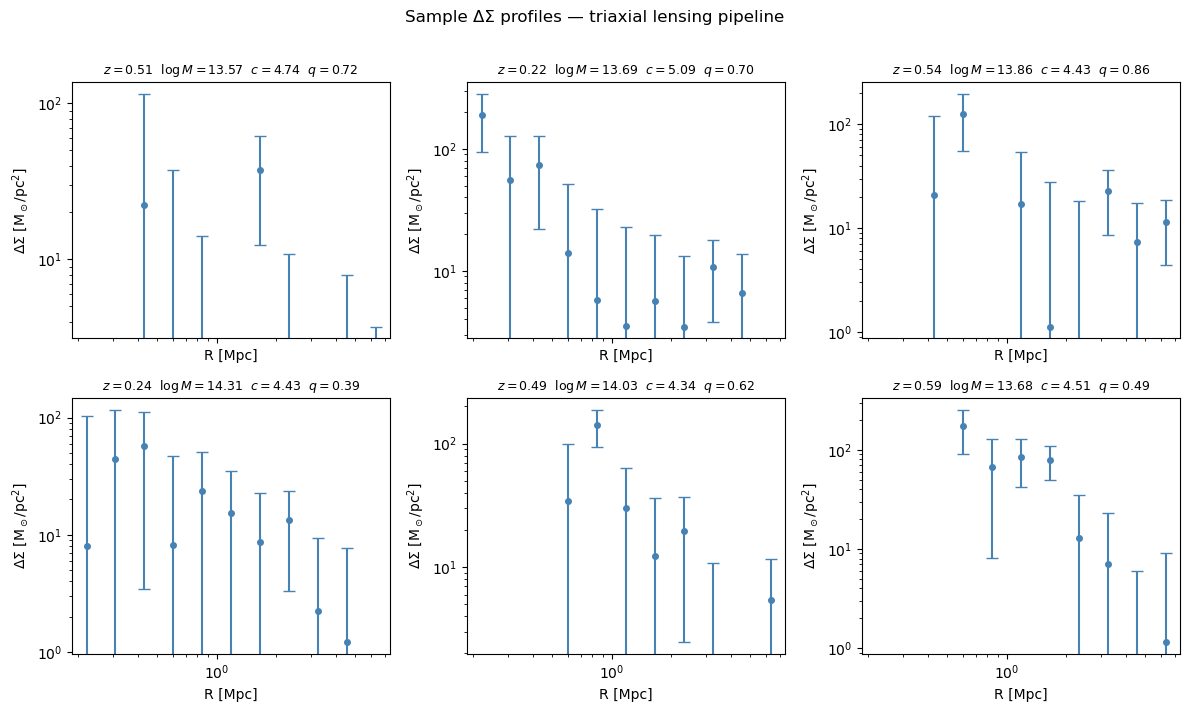

In [8]:
# Sanity check — six example profiles
idx = np.round(np.linspace(0, N_CLUSTERS - 1, 6)).astype(int)
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True)

for ax, i in zip(axes.ravel(), idx):
    errs = np.sqrt(np.diag(cov_matrices[i]))
    real = errs < np.sqrt(NOISE_FLOOR_COV)
    ax.errorbar(RADII[real], data_vectors[i, real], yerr=errs[real],
                fmt='o', markersize=4, capsize=4, color='steelblue')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_title(
        rf'$z={truth["z"][i]:.2f}$  '
        rf'$\log M={np.log10(truth["M_halo"][i]):.2f}$  '
        rf'$c={truth["concentration"][i]:.2f}$  '
        rf'$q={q_min_arr[i]/q_maj_arr[i]:.2f}$',
        fontsize=9,
    )
    ax.set_xlabel('R [Mpc]')
    ax.set_ylabel(r'$\Delta\Sigma$ [M$_\odot$/pc$^2$]')

plt.suptitle('Sample ΔΣ profiles — triaxial lensing pipeline', y=1.01)
plt.tight_layout(); plt.show()

## 4 — Cluster observable table

Richness is computed from the true mass via the McClintock+18 inversion with
`poisson_richness=False` — no Poisson scatter — to isolate triaxiality as the
only systematic in the recovery.

In [9]:
# make_test_data is used only for the Lambda assignment; we discard its
# synthetic data_vectors and cov_matrices and use the triaxial ones.
cluster_obs, _, _ = make_test_data(
    truth, RADII,
    fractional_noise=0.2,
    poisson_richness=False,
    seed=SEED + 1,
)

print(f'Observable columns: {cluster_obs.colnames}')
print(f'Richness range: {cluster_obs["Lambda"].min():.1f} – {cluster_obs["Lambda"].max():.1f}')
cluster_obs[:5]

Observable columns: ['z', 'Lambda', 'delta_m']
Richness range: 6.6 – 94.7


z,Lambda,delta_m
float64,float64,float64
0.5095824194223852,9.112846695110028,0.4835503617253429
0.3755513759008209,12.927533914116554,0.11382018941124342
0.5434391679645529,15.715895914742012,0.6243702902139779
0.47894721162374554,8.722921334033332,0.08644851284268604
0.23767093915505982,6.987749387888987,2.533591651154298


## 5 — Run the sampler

Fits $(c_0, \alpha, \beta, \log M_{\rm norm})$ jointly against the triaxially-simulated
$\Delta\Sigma$ profiles.  Priors are wide Gaussians.  The forward model is spherical NFW.

In [10]:
sampler = run_sampler_mc(
    cluster_obs,
    data_vectors,
    cov_matrices,
    RADII,
    c0_prior_loc=5.0,
    c0_prior_scale=5.0,
    alpha_prior_loc=0.0,
    alpha_prior_scale=0.5,
    beta_prior_loc=0.0,
    beta_prior_scale=1.0,
    fit_beta=True,
    n_live=300,
    pool=15,
    verbose=True,
)

Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 21     | 1        | 4        | 14385    | N/A    | 10045 | -301158.7


## 6 — Posterior analysis

In [11]:
points, log_w, log_l = sampler.posterior()
weights = np.exp(log_w - log_w.max())
weights /= weights.sum()

c0_s    = points[:, 0]
alpha_s = points[:, 1]
beta_s  = points[:, 2]
MN_s    = points[:, 3]

def wq(v, q):
    sorter = np.argsort(v)
    cs = np.cumsum(weights[sorter]) / weights.sum()
    return np.interp(q, cs, v[sorter])

results = {}
for name, samp, truth_val in [
    ('c0',    c0_s,    c0_true),
    ('alpha', alpha_s, alpha_true),
    ('beta',  beta_s,  beta_true),
    ('log_M_norm', MN_s, 0.0),
]:
    lo, md, hi = wq(samp, 0.16), wq(samp, 0.50), wq(samp, 0.84)
    sigma = (hi - lo) / 2
    bias  = (md - truth_val) / sigma if sigma > 0 else np.nan
    results[name] = (lo, md, hi, truth_val, bias)
    print(f'{name:12s}: {md:+.4f}  −{md-lo:.4f}  +{hi-md:.4f}   '
          f'truth={truth_val:+.4f}   bias={bias:+.2f}σ')

c0          : +4.6014  −0.1114  +0.1130   truth=+4.5664   bias=+0.31σ
alpha       : -0.0593  −0.0249  +0.0235   truth=-0.0909   bias=+1.31σ
beta        : -0.5955  −0.2671  +0.2745   truth=-0.4687   bias=-0.47σ
log_M_norm  : -0.0207  −0.0064  +0.0063   truth=+0.0000   bias=-3.25σ


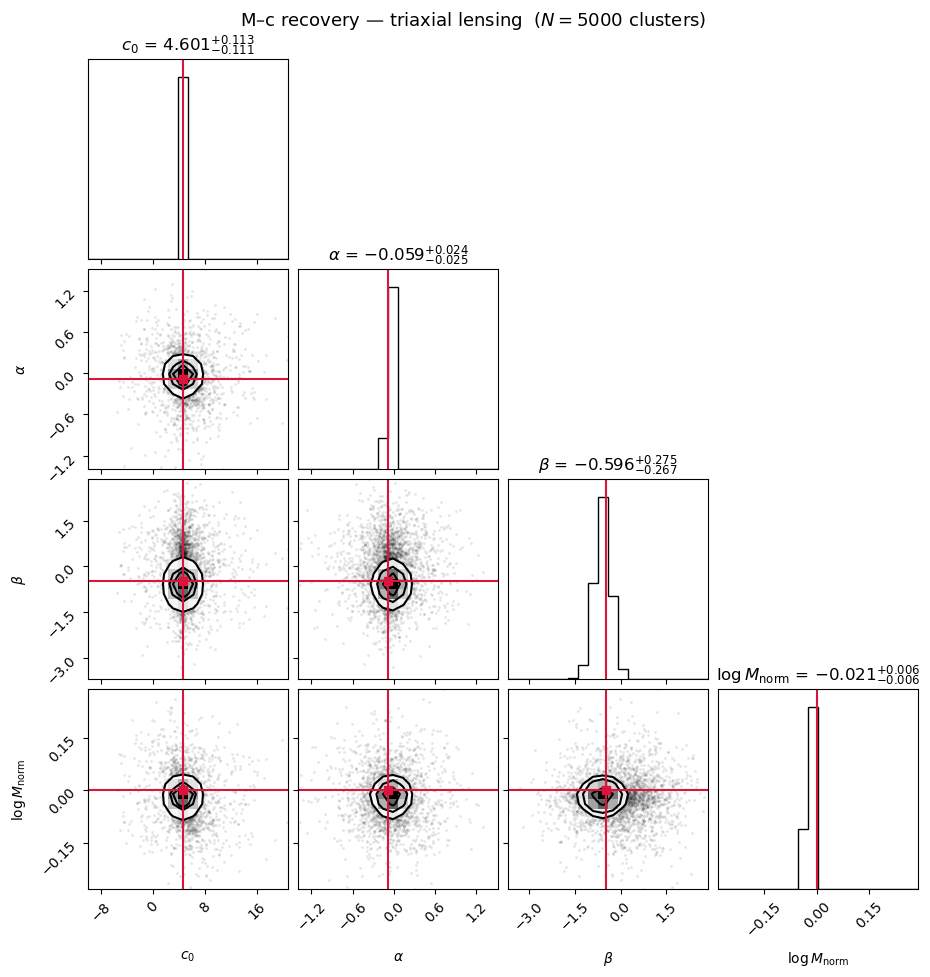

In [12]:
if corner is not None:
    labels = [
        r'$c_0$',
        r'$\alpha$',
        r'$\beta$',
        r'$\log M_{\rm norm}$',
    ]
    truths = [c0_true, alpha_true, beta_true, 0.0]

    fig = corner.corner(
        points,
        weights=weights,
        labels=labels,
        truths=truths,
        truth_color='crimson',
        show_titles=True,
        title_fmt='.3f',
        smooth=1.0,
    )
    plt.suptitle(
        rf'M–c recovery — triaxial lensing  ($N={N_CLUSTERS}$ clusters)',
        y=1.01, fontsize=13,
    )
    plt.savefig('mc_posterior_triaxial.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('Install corner for the triangle plot: pip install corner')

## 7 — M–c recovery band

Posterior samples of $\log_{10}c = \log_{10}c_0 + \alpha(\log_{10}M - 14) + \beta\log_{10}((1+z_{\rm med})/(1+z_{\rm ref}))$
compared to the true Dutton–Maccio curve and the truth catalog scatter.

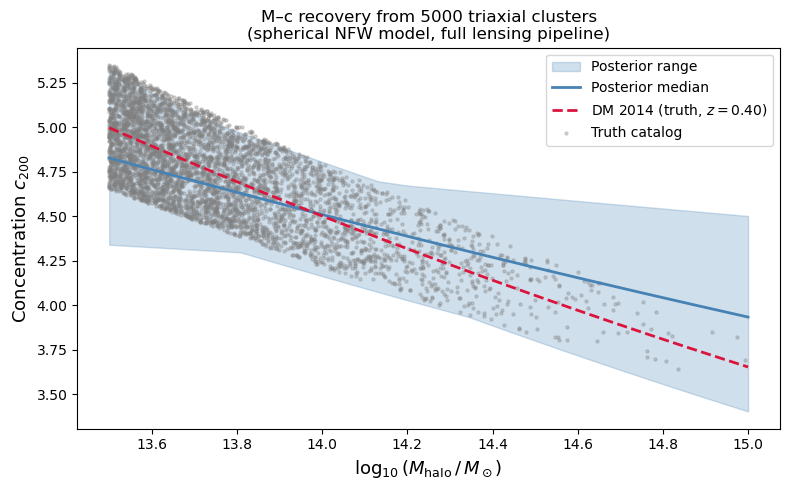


--- Summary ---
  c0          : recovered +4.6014  truth +4.5664  bias +0.31σ  [OK]
  alpha       : recovered -0.0593  truth -0.0909  bias +1.31σ  [OK]
  beta        : recovered -0.5955  truth -0.4687  bias -0.47σ  [OK]
  log_M_norm  : recovered -0.0207  truth +0.0000  bias -3.25σ  [BIASED]


In [13]:
M_grid   = np.logspace(13.5, 15.0, 200)
z_med    = float(np.median(truth['z']))
logM_g   = np.log10(M_grid)
logz1_g  = np.log10((1 + z_med) / (1 + _MC_Z_REF))

# Draw 200 posterior samples for the band
rng_plot = np.random.default_rng(0)
idx_band = rng_plot.choice(len(c0_s), size=200,
                           p=weights / weights.sum(), replace=True)

fig, ax = plt.subplots(figsize=(8, 5))

# Posterior band
C_band = np.array([
    10.0 ** (np.log10(c0_s[k]) + alpha_s[k] * (logM_g - _MC_M_PIVOT_LOG)
             + beta_s[k] * logz1_g)
    for k in idx_band
])
ax.fill_between(logM_g, C_band.min(0), C_band.max(0),
                alpha=0.25, color='steelblue', label='Posterior range')

# Posterior median
lo_c, md_c, hi_c, _, _ = results['c0']
lo_a, md_a, hi_a, _, _ = results['alpha']
lo_b, md_b, hi_b, _, _ = results['beta']
C_med = 10.0 ** (np.log10(md_c) + md_a * (logM_g - _MC_M_PIVOT_LOG) + md_b * logz1_g)
ax.plot(logM_g, C_med, 'steelblue', lw=2, label=r'Posterior median')

# True DM curve at median z
C_true = c_DuttonMaccio(z_med * np.ones(200), M_grid)
ax.plot(logM_g, C_true, 'crimson', lw=2, ls='--',
        label=rf'DM 2014 (truth, $z={z_med:.2f}$)')

# Truth scatter
ax.scatter(logM_s, truth['concentration'],
           s=5, alpha=0.3, color='grey', rasterized=True, label='Truth catalog')

ax.set_xlabel(r'$\log_{10}(M_{\rm halo}\,/\,M_\odot)$', fontsize=13)
ax.set_ylabel(r'Concentration $c_{200}$', fontsize=13)
ax.set_title(
    rf'M–c recovery from {N_CLUSTERS} triaxial clusters'
    '\n(spherical NFW model, full lensing pipeline)',
    fontsize=12,
)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig('mc_recovery_triaxial.png', dpi=150)
plt.show()

print('\n--- Summary ---')
for name, (lo, md, hi, tv, bias) in results.items():
    flag = 'OK' if abs(bias) < 2 else 'BIASED'
    print(f'  {name:12s}: recovered {md:+.4f}  truth {tv:+.4f}  bias {bias:+.2f}σ  [{flag}]')

In [14]:
 results['c0']

(np.float64(4.489971837288418),
 np.float64(4.601407951589387),
 np.float64(4.714403167277595),
 np.float64(4.566394452137475),
 np.float64(0.31201971180762017))